## Task 5: ClimateBench scores for all models

Spatial, global and total NRMSE over 2080–2100 against the ssp245 ensemble mean (cos-latitude weighted),
plus prediction − truth difference maps for every model and target.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from metrics import nrmse_scores

**paths and constants**

In [5]:
# ClimateBench data folder -- edit to wherever outputs_ssp245.nc lives on your machine
DATA_PATH = Path("~/private/180A").expanduser()

# repo root (this notebook lives in week3/coleman/)
REPO = Path("../..")

RF_FILE  = REPO / "week3/cheryl/rf_results/rf_predictions_ssp245.nc"
CNN_DIR  = REPO / "week3/cheryl/cnn_results"
GP_FILE  = REPO / "week3/jennifer/gp_results/gp_predictions_ssp245.nc"          # not saved yet
PS_FILES = {                                                                    # see note below
    "Pattern scaling (oracle GMT)": REPO / "vishal_rana/outputs_ssp245_prediction_pattern_scaling.nc",
    "Pattern scaling (CO2-driven GMT)": REPO / "vishal_rana/outputs_ssp245_prediction_pattern_scaling_inputs.nc",
}

SECONDS_PER_DAY = 86400
SEEDS = [0, 1, 2, 3, 4]

VARS  = {"tas": "tas", "dtr": "diurnal_temperature_range", "pr": "pr", "pr90": "pr90"}
UNITS = {"tas": "K", "dtr": "K", "pr": "mm/day", "pr90": "mm/day"}

**load ssp245 truth (ensemble mean, precip in mm/day)**

In [6]:
truth = xr.open_dataset(DATA_PATH / "outputs_ssp245.nc").mean("member").sel(time=slice(2015, 2100)).compute()
truth["pr"]   = truth["pr"] * SECONDS_PER_DAY
truth["pr90"] = truth["pr90"] * SECONDS_PER_DAY
truth = truth[list(VARS.values())]
print(dict(truth.sizes))

{'time': 86, 'lat': 96, 'lon': 144}


**helper to put every model's predictions on the truth's grid**

Renames `latitude`/`longitude` → `lat`/`lon`, turns dates into integer years, and snaps lat/lon onto the truth's
coordinates (xarray only matches exactly equal values, so tiny float differences would silently drop grid cells).
Raises if precip still looks like kg/m²/s.

In [7]:
def standardize(ds, name):
    ds = ds.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon", "dtr": "diurnal_temperature_range"}.items()
                    if k in ds.variables})

    # time -> integer years
    if ds.time.dtype.kind == "M":
        ds["time"] = ds.time.dt.year.values
    elif ds.time.dtype == object:                       # cftime dates
        ds["time"] = [t.year for t in ds.time.values]
    ds = ds.sel(time=slice(2015, 2100))

    # same grid as truth
    assert np.allclose(ds.lat, truth.lat) and np.allclose(ds.lon, truth.lon), f"{name}: lat/lon grid differs from truth"
    ds = ds.assign_coords(lat=truth.lat, lon=truth.lon)

    # precip must be mm/day like the truth (anomalies in kg/m2/s are ~1e-6)
    for v in ["pr", "pr90"]:
        if float(abs(ds[v]).mean()) < 1e-3:
            raise ValueError(f"{name}: {v} looks like kg/m2/s -- multiply by {SECONDS_PER_DAY}")

    return ds[list(VARS.values())].transpose("time", "lat", "lon").compute()


def from_npy(arrays):
    """{var: (86, 96, 144) array} -> Dataset with the truth's coords."""
    return xr.Dataset({v: (("time", "lat", "lon"), a) for v, a in arrays.items()},
                      coords={"time": truth.time, "lat": truth.lat, "lon": truth.lon})

**load model predictions**

- Pattern scaling: the committed `.nc` isn't written by any cell in Vishal's notebook, so check with him which GMT
  (oracle or CO2-driven) it used. The CO2-driven file doesn't exist yet.
- GP: Jennifer's notebook doesn't save predictions yet, so it's skipped until `GP_FILE` exists.
- CNN-LSTM: the main row is the seed-mean prediction; per-seed predictions are kept in `cnn_seed_preds` for the spread.

In [10]:
preds = {}

for name, f in PS_FILES.items():
    if f.exists():
        preds[name] = standardize(xr.open_dataset(f), name)
    else:
        print("missing:", f)

if GP_FILE.exists():
    preds["Gaussian process"] = standardize(xr.open_dataset(GP_FILE), "Gaussian process")
else:
    print("missing:", GP_FILE)

preds["Random forest"] = standardize(xr.open_dataset(RF_FILE), "Random forest")

cnn_seed_preds = {s: from_npy({v: np.load(CNN_DIR / f"pred_{v}_seed{s}.npy") for v in VARS.values()})
                  for s in SEEDS}
preds["CNN-LSTM (seed mean)"] = sum(cnn_seed_preds.values()) / len(SEEDS)

for name, ds in preds.items():
    print(f"{name:35s} {dict(ds.sizes)}")

missing: ../../vishal_rana/outputs_ssp245_prediction_pattern_scaling_inputs.nc
Pattern scaling (oracle GMT)        {'time': 86, 'lat': 96, 'lon': 144}
Gaussian process                    {'time': 86, 'lat': 96, 'lon': 144}
Random forest                       {'time': 86, 'lat': 96, 'lon': 144}
CNN-LSTM (seed mean)                {'time': 86, 'lat': 96, 'lon': 144}


In [9]:
from metrics import global_mean

ps = preds["Pattern scaling (oracle GMT)"]
gmt_used    = global_mean(ps["tas"]).to_series()
gmt_truth   = global_mean(truth["tas"]).to_series()
gmt_rolling = gmt_truth.rolling(10, min_periods=1).mean()

print("max diff vs truth GMT, 10-yr rolling:", float(abs(gmt_used - gmt_rolling).max()))
print("max diff vs truth GMT, unsmoothed:   ", float(abs(gmt_used - gmt_truth).max()))


max diff vs truth GMT, 10-yr rolling: 2.4424906541753444e-15
max diff vs truth GMT, unsmoothed:    0.27646168590181563


**results table**

In [11]:
rows = []
for model, ds in preds.items():          # e.g. {"Pattern scaling": ds_ps, "GP": ds_gp, ...}
    for short, var in VARS.items():
        rows.append({"model": model, "variable": short, **nrmse_scores(truth[var], ds[var])})

table = (pd.DataFrame(rows)
           .pivot(index="model", columns="variable", values=["spatial", "global", "total"])
           .swaplevel(axis=1).sort_index(axis=1)
           .reindex(columns=["tas", "dtr", "pr", "pr90"], level=0))


In [12]:
table.to_csv("scores_all_models.csv")
table.round(3)

variable                        tas                   dtr                  \
                             global spatial  total global spatial   total   
model                                                                       
CNN-LSTM (seed mean)          0.071   0.097  0.453  1.359   7.890  14.683   
Gaussian process              0.039   0.089  0.284  2.195   9.476  20.454   
Pattern scaling (oracle GMT)  0.048   0.080  0.320  2.327   8.083  19.719   
Random forest                 0.163   0.086  0.900  2.947  14.279  29.014   

variable                         pr                  pr90                 
                             global spatial  total global spatial  total  
model                                                                     
CNN-LSTM (seed mean)          0.240   1.972  3.170  0.312   2.568  4.127  
Gaussian process              0.353   2.324  4.088  0.450   2.718  4.970  
Pattern scaling (oracle GMT)  0.331   2.006  3.662  0.412   2.400  4.461  
Random forest                 0.511   2.764  5.317  0.583   3.125  6.039

**difference maps (prediction − truth, 2080–2100 mean)**

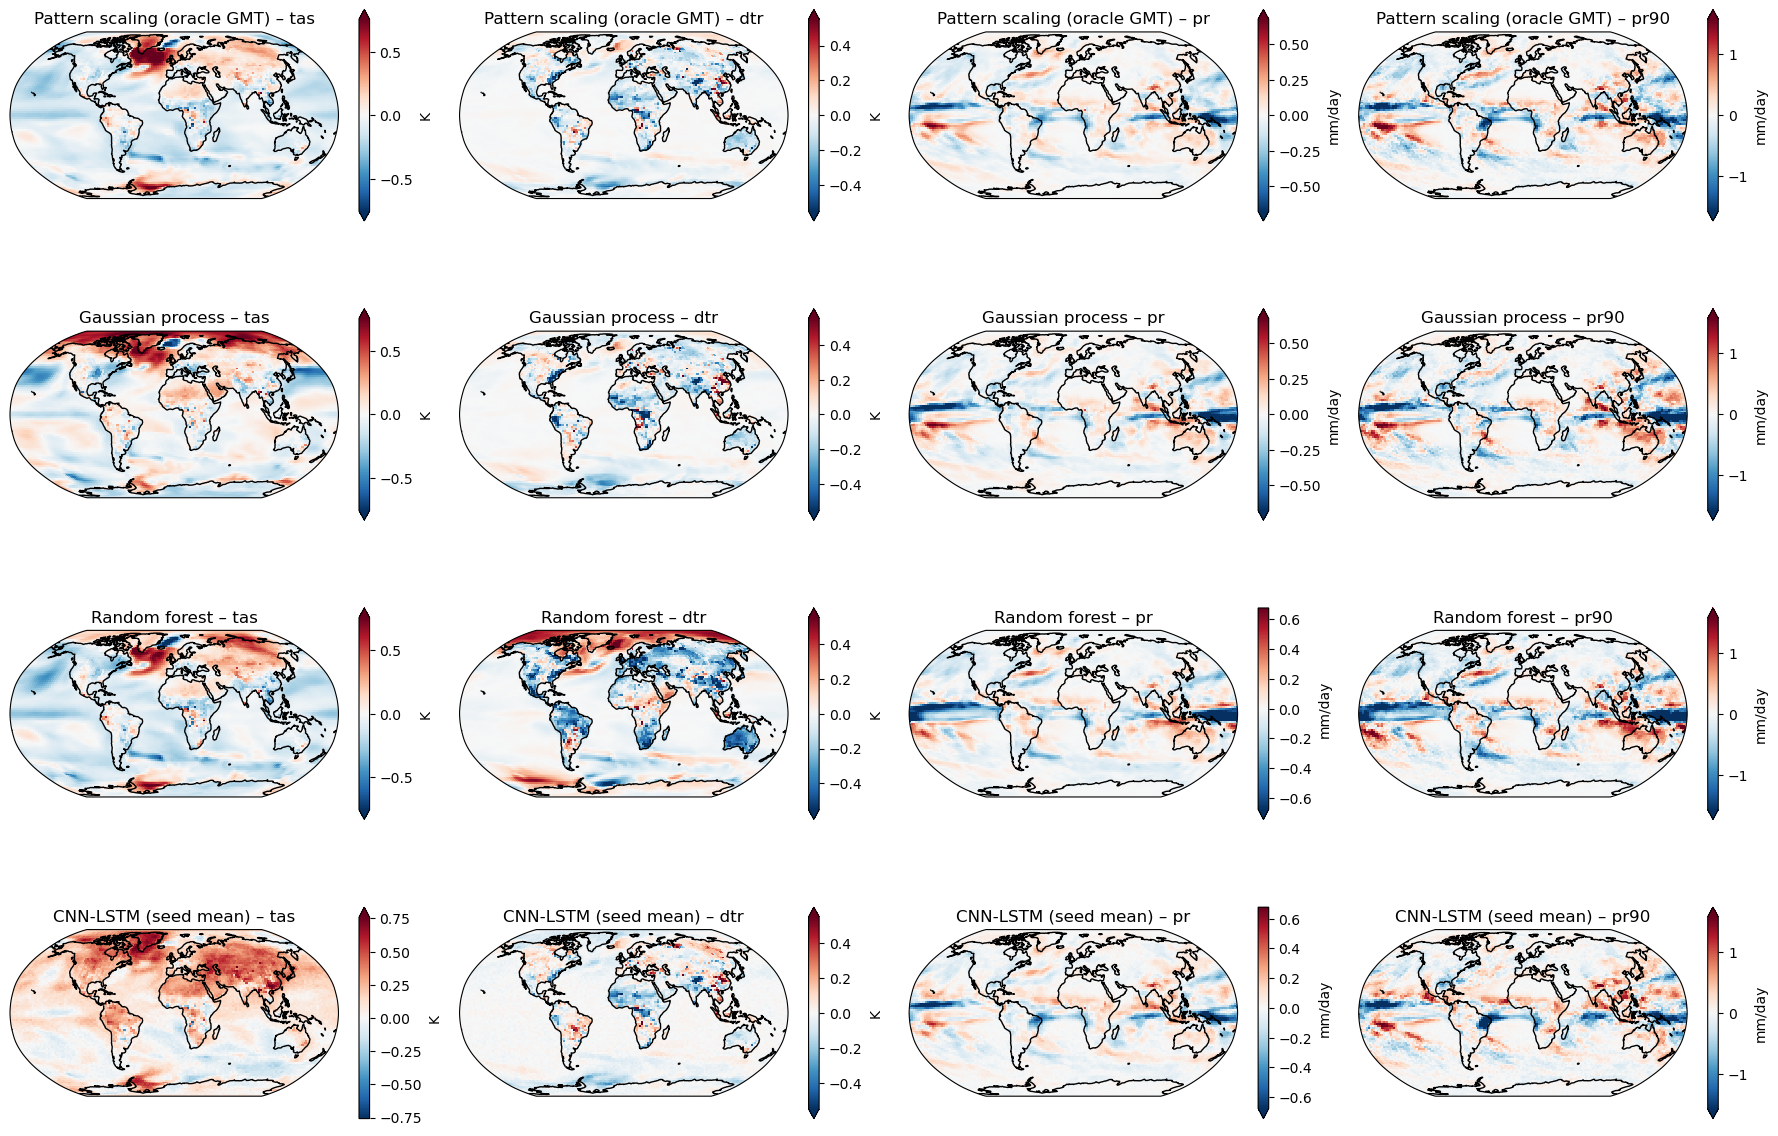

In [13]:
import cartopy.crs as ccrs
fig, axs = plt.subplots(len(preds), 4, figsize=(18, 3.2 * len(preds)),
                        subplot_kw={"projection": ccrs.Robinson()})
for j, (short, var) in enumerate(VARS.items()):
    t = truth[var].sel(time=slice(2080, 2100)).mean("time")
    diffs = {m: ds[var].sel(time=slice(2080, 2100)).mean("time") - t for m, ds in preds.items()}
    vmax = max(float(abs(d).quantile(0.99)) for d in diffs.values())   # shared scale per target
    for i, (m, d) in enumerate(diffs.items()):
        d.plot(ax=axs[i, j], transform=ccrs.PlateCarree(), cmap="RdBu_r",
               vmin=-vmax, vmax=vmax, cbar_kwargs={"shrink": 0.6, "label": UNITS[short]})
        axs[i, j].coastlines(); axs[i, j].set_title(f"{m} – {short}")
plt.tight_layout(); plt.savefig("diff_maps_all_models.png", dpi=120)
